Домашнее задание по теме 5

$\textbf{Часть 1}$

а) укажите значение статистики критерия хи-квадрат (с двумя знаками после запятой) и 
соответствующее p-value;  

In [21]:
import pandas as pd
import numpy as np
from scipy.stats import chisquare

df = pd.read_table('Caith.txt', decimal=' ')
df

,Words,Brown,CELEX
0,the,69971,1093547
1,president,382,2469
2,hare,1,153
3,harpsichord,1,16
4,Other,929645,17483936


In [22]:
x = df['Brown'] ## наблюдаемые количества слов из корпуса Brown
z = df['CELEX'] ## количества слов из более большого корпуса CELEX

p0 = z/(z.sum())
y = p0 * x.sum()
stat, p = chisquare(x, y)
print(stat.round(2),p)

2709.65 0.0


б) проверьте для ожидаемых количеств выполнение условия $𝑛𝑝_{𝑗}^{0} ≥ 5$;

In [23]:
y

0     58855.752339
1       132.883957
2         8.234607
3         0.861135
4    941002.267962
Name: CELEX, dtype: float64

Для слова harpsichord условие не выполнено.

в) укажите значение статистики критерия хи-квадрат и соответствующее p-value, полученные после 
исключения слова «harpsichord», и сделайте вывод, отвергается ли на уровне значимости 0,001 
гипотеза согласия наблюдаемых и ожидаемых количеств. 

In [24]:
x_new = np.delete(x,3)
z_new = np.delete(z,3)
p0_new = z_new/(z_new.sum())
y_new = p0_new * x_new.sum()
stat, p = chisquare(x_new, y_new)
print(stat.round(2),p)

2709.62 0.0


Вывод: на уровне значимости 0,001 гипотеза согласия отвергается.

$\textbf{Часть 2}$

а) постройте графики (ломаные линии) и укажите p-value критерия хи-квадрат при проверке 
однородности каждой из двух групп; 

In [25]:
df = pd.read_table('PetrolVal.txt',decimal=' ')
df

,Categ,BP,Lukoil,MTK,Sibneft,Tatneft,TNK,Ukos
0,1-3,"6,474820144","6,923076923","13,69863014","13,39285714","18,82352941","6,737588652","12,98701299"
1,4-5,"20,14388489","22,30769231","34,24657534","36,60714286","27,05882353","19,5035461","31,81818182"
2,6-7,"73,38129496","70,76923077","52,05479452",50,"54,11764706","73,75886525","55,19480519"


In [26]:
df.dtypes

Categ      object
BP         object
Lukoil     object
MTK        object
Sibneft    object
Tatneft    object
TNK        object
Ukos       object
dtype: object

In [27]:
df = df.drop(columns = ['Categ'])
for col in df:
    df[col] = df[col].str.replace(',', '.').astype(float)
df

,BP,Lukoil,MTK,Sibneft,Tatneft,TNK,Ukos
0,6.474820,6.923077,13.698630,13.392857,18.823529,6.737589,12.987013
1,20.143885,22.307692,34.246575,36.607143,27.058824,19.503546,31.818182
2,73.381295,70.769231,52.054795,50.000000,54.117647,73.758865,55.194805


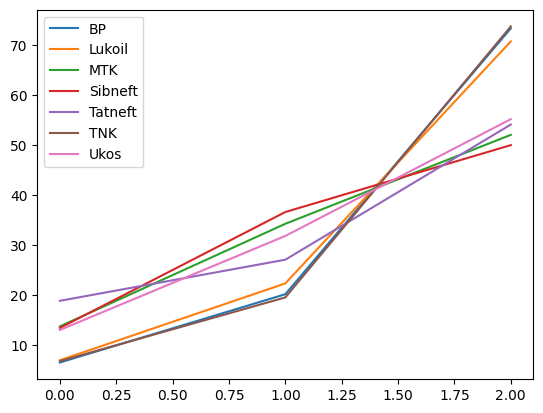

In [28]:
import matplotlib.pyplot as plt

for col in df:
    plt.plot([0,1,2],df[col], label=col)
plt.legend()
plt.show()

На основе графика могу разделить на две группы:
1) BP, TNK, Lukoil, Tatneft
2) MTK, Sibneft, Ukos

In [29]:
from scipy.stats import chi2_contingency

group_A = ['BP', 'Lukoil', 'TNK' , 'Tatneft']
group_B = ['MTK', 'Sibneft', 'Ukos']

table_A = df[group_A].T.values
stat_A, p_A, dof_A, expected_A = chi2_contingency(table_A)
print(p_A)

table_B = df[group_B].T.values
stat_B, p_B, dof_B, expected_B = chi2_contingency(table_B)
print(p_B)

0.010271399989778704
0.9613457923719737


Вывод: на уровне 0.05 гипотеза об однородности первой группы отклоняется.

б) объясните противоречие между построенными графиками и выводами на основе критерия         
хи-квадрат; 

График Tatneft ошибично попал в 1 группу. 

Хоть график похож на 1 группу, судя по значениям он гораздо лучше подходит 2 группе.

в) предложите более правильную сегментацию фирм АЗС и обоснуйте её. 

Как я уже сказал, есть судить исключительно по таблице (не смотря на график), то кажется что Tatneft гораздо больше подходит во 2 группу.
Пересчитаем для новых групп:

In [30]:
group_A = ['BP', 'Lukoil', 'TNK' ]
group_B = ['MTK', 'Sibneft', 'Ukos','Tatneft']

table_A = df[group_A].T.values
stat_A, p_A, dof_A, expected_A = chi2_contingency(table_A)
print(p_A)

table_B = df[group_B].T.values
stat_B, p_B, dof_B, expected_B = chi2_contingency(table_B)
print(p_B)

0.9899937694948098
0.760012151912867


Действительно: теперь критерий хи-квадрат не может отвергнуть гипотезу однородности.